In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

ratings = pd.read_csv("../data/ml-32m/ratings.csv")
movies  = pd.read_csv("../data/ml-32m/movies.csv")
links   = pd.read_csv("../data/ml-32m/links.csv")

print("Ratings:", ratings.shape)
print("Movies:", movies.shape)
print("Links:", links.shape)

print(ratings.head())

Ratings: (32000204, 4)
Movies: (87585, 3)
Links: (87585, 3)
   userId  movieId  rating  timestamp
0       1       17     4.0  944249077
1       1       25     1.0  944250228
2       1       29     2.0  943230976
3       1       30     5.0  944249077
4       1       32     5.0  943228858


count    200948.000000
mean        159.246193
std         282.025462
min          20.000000
25%          36.000000
50%          73.000000
75%         167.000000
max       33332.000000
dtype: float64
20+ ratings: 200,948 users
30+ ratings: 166,757 users
50+ ratings: 128,344 users
75+ ratings: 98,697 users
100+ ratings: 80,675 users
200+ ratings: 42,197 users
500+ ratings: 12,603 users


Text(0, 0.5, 'Number of Users (log scale)')

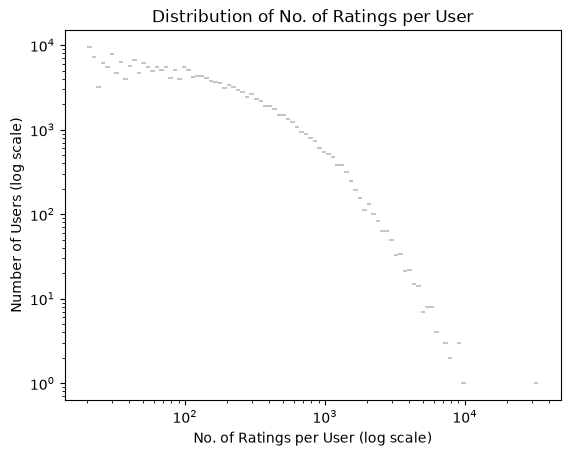

In [50]:
ratings_per_user = ratings.groupby("userId").size()

print(ratings_per_user.describe())

for threshold in [20, 30, 50, 75, 100, 200, 500]:
    n_users = (ratings_per_user >= threshold).sum()
    print(f"{threshold}+ ratings: {n_users:,} users")

sns.histplot(ratings_per_user, bins=100, log_scale=(True, True))
plt.title("Distribution of No. of Ratings per User")
plt.xlabel("No. of Ratings per User (log scale)")
plt.ylabel("Number of Users (log scale)")

Filtered User Ratings: (2630698, 4)
Train Ratings: (2104558, 4)
Test Ratings: (526140, 4)
     userId  movieId  rating   timestamp
193       3        2     3.5  1084485210
194       3       10     4.0  1084484675
195       3       11     4.0  1084485789
196       3       17     5.0  1084485217
197       3       26     4.0  1084486051

              userId       movieId        rating     timestamp
count  2.630698e+06  2.630698e+06  2.630698e+06  2.630698e+06
mean   1.014369e+05  2.801356e+04  3.569307e+00  1.274750e+09
std    5.846123e+04  4.884024e+04  1.045313e+00  2.507146e+08
min    3.000000e+00  1.000000e+00  5.000000e-01  8.228736e+08
25%    5.043000e+04  1.259000e+03  3.000000e+00  1.053562e+09
50%    1.022760e+05  3.418000e+03  4.000000e+00  1.255671e+09
75%    1.519290e+05  4.081900e+04  4.000000e+00  1.501238e+09
max    2.009400e+05  2.924770e+05  5.000000e+00  1.697158e+09

Ratings per Filtered User:
 count    10000.000000
mean       263.069800
std        179.373473
min      

Text(0, 0.5, 'Number of Users')

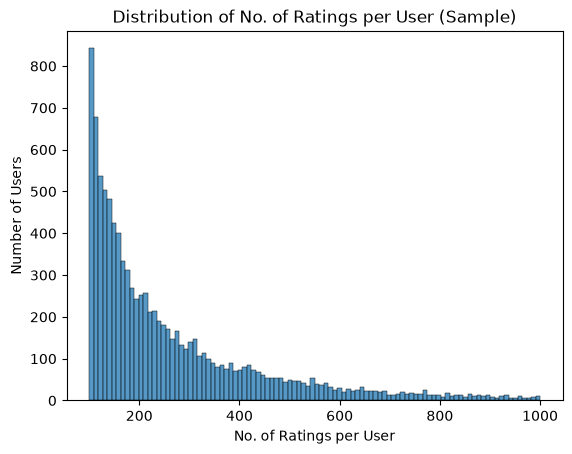

In [51]:
#sample
# previously filtered between 50 and 1000
filtered_users = ratings_per_user[(ratings_per_user >= 100) & (ratings_per_user <= 1000)]
filtered_users_sample = filtered_users.sample(n=10000, random_state=1)

#pipeline test
filtered_users_sample2 = filtered_users[
    ~filtered_users.index.isin(filtered_users_sample.index)
].sample(n=1000, random_state=1)

filtered_ratings = ratings[ratings["userId"].isin(filtered_users_sample.index)]

# export filtered ratings 2 to pipeline
filtered_ratings2 = ratings[ratings["userId"].isin(filtered_users_sample2.index)]
filtered_ratings2.to_csv(
    "../data/filtered_ratings2.csv",
    index=False
)

train_ratings, test_ratings = train_test_split(
    filtered_ratings,
    test_size=0.2,
    random_state=42,
)

print("Filtered User Ratings:", filtered_ratings.shape)
print("Train Ratings:", train_ratings.shape)
print("Test Ratings:", test_ratings.shape)
print(filtered_ratings.head())
print("\n", filtered_ratings.describe())

#export training/test ratings to do ndcg eval
train_ratings.to_csv(
    "../data/train_ratings.csv",
    index=False
)
test_ratings.to_csv(
    "../data/test_ratings.csv",
    index=False
)

#per user data
ratings_per_filtered_user = filtered_ratings.groupby("userId").size()
print("\nRatings per Filtered User:\n", ratings_per_filtered_user.describe())

sns.histplot(ratings_per_filtered_user, bins=100, log_scale=(False, False))
plt.title("Distribution of No. of Ratings per User (Sample)")
plt.xlabel("No. of Ratings per User")
plt.ylabel("Number of Users")


Text(0, 0.5, 'Number of Users')

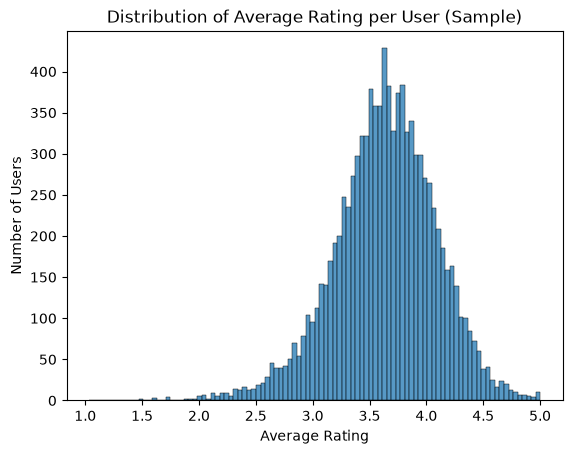

In [52]:
#plot user average rating 
#to be standardised (normalised?)
user_average_ratings = filtered_ratings.groupby("userId")["rating"].mean()

sns.histplot(user_average_ratings, bins=100, log_scale=(False, False))
plt.title("Distribution of Average Rating per User (Sample)")
plt.xlabel("Average Rating")
plt.ylabel("Number of Users")

#plot genre average?

In [53]:
#movies filter
selected_movies_id = train_ratings["movieId"].unique()
movies_filtered = movies[movies["movieId"].isin(selected_movies_id)]

print("Filtered Movies:", movies_filtered.shape[0])

Filtered Movies: 28160


In [54]:
# full dataset: all users with 50-1000 ratings (no sampling)
#filtered_users = ratings_per_user[(ratings_per_user >= 50) & (ratings_per_user <= 1000)]
#
#filtered_ratings = ratings[ratings["userId"].isin(filtered_users.index)]

# Production: fit on every rating. Set False to get the 80/20 split for evaluation.
#SHIP = True

#if SHIP:
#    train_ratings = filtered_ratings
#    test_ratings = filtered_ratings.iloc[0:0]  # empty, nothing held out
#else:
#    train_ratings, test_ratings = train_test_split(
#        filtered_ratings,
#        test_size=0.2,
#        random_state=42,
#    )

#print("Filtered Users:", filtered_users.shape[0])
#print("Filtered User Ratings:", filtered_ratings.shape)
#print("Train Ratings:", train_ratings.shape)
#print("Test Ratings:", test_ratings.shape)
#print(filtered_ratings.head())
#print("\n", filtered_ratings.describe())

# export to the same paths 
#train_ratings.to_csv("../data/train_ratings.csv", index=False)
#test_ratings.to_csv("../data/test_ratings.csv", index=False)

In [55]:
genre_encoded = movies_filtered["genres"].str.get_dummies(sep="|")

movies_encoded = pd.concat(
    [movies_filtered, genre_encoded],
    axis=1,
)

movies_encoded = movies_encoded.drop(columns=["genres", "(no genres listed)"])

print(movies_encoded.head())

   movieId                               title  Action  Adventure  Animation  \
0        1                    Toy Story (1995)       0          1          1   
1        2                      Jumanji (1995)       0          1          0   
2        3             Grumpier Old Men (1995)       0          0          0   
3        4            Waiting to Exhale (1995)       0          0          0   
4        5  Father of the Bride Part II (1995)       0          0          0   

   Children  Comedy  Crime  Documentary  Drama  ...  Film-Noir  Horror  IMAX  \
0         1       1      0            0      0  ...          0       0     0   
1         1       0      0            0      0  ...          0       0     0   
2         0       1      0            0      0  ...          0       0     0   
3         0       1      0            0      1  ...          0       0     0   
4         0       1      0            0      0  ...          0       0     0   

   Musical  Mystery  Romance  Sci-Fi  

In [56]:
#clean title and extract release year

movies_encoded["Release_Year"] = (movies_encoded["title"].str.extract(r"\((\d{4})\)$")[0])
movies_encoded["Release_Year"] = pd.to_numeric(movies_encoded["Release_Year"], errors="coerce")
movies_encoded["title_clean"] = (movies_encoded["title"].str.replace(r"\s*\(\d{4}\)$", "", regex=True))
movies_encoded = movies_encoded.drop(columns=["title"])

print(movies_encoded.shape)
print(movies_encoded.head())

(28160, 22)
   movieId  Action  Adventure  Animation  Children  Comedy  Crime  \
0        1       0          1          1         1       1      0   
1        2       0          1          0         1       0      0   
2        3       0          0          0         0       1      0   
3        4       0          0          0         0       1      0   
4        5       0          0          0         0       1      0   

   Documentary  Drama  Fantasy  ...  IMAX  Musical  Mystery  Romance  Sci-Fi  \
0            0      0        1  ...     0        0        0        0       0   
1            0      0        1  ...     0        0        0        0       0   
2            0      0        0  ...     0        0        0        1       0   
3            0      1        0  ...     0        0        0        1       0   
4            0      0        0  ...     0        0        0        0       0   

   Thriller  War  Western  Release_Year                  title_clean  
0         0    0     

In [57]:
#add avg rating to movie feature matrix

avg_ratings = train_ratings.groupby("movieId")["rating"].mean().rename("avg_rating")
movies_encoded = movies_encoded.merge(avg_ratings, on="movieId", how="left")

print(movies_encoded.head())

   movieId  Action  Adventure  Animation  Children  Comedy  Crime  \
0        1       0          1          1         1       1      0   
1        2       0          1          0         1       0      0   
2        3       0          0          0         0       1      0   
3        4       0          0          0         0       1      0   
4        5       0          0          0         0       1      0   

   Documentary  Drama  Fantasy  ...  Musical  Mystery  Romance  Sci-Fi  \
0            0      0        1  ...        0        0        0       0   
1            0      0        1  ...        0        0        0       0   
2            0      0        0  ...        0        0        1       0   
3            0      1        0  ...        0        0        1       0   
4            0      0        0  ...        0        0        0       0   

   Thriller  War  Western  Release_Year                  title_clean  \
0         0    0        0        1995.0                    Toy Story

In [58]:
# testing decade
movies_encoded["Decade"] = (movies_encoded["Release_Year"] // 10) * 10
decade_avg_ratings = movies_encoded.groupby("Decade")["avg_rating"].mean().rename("decade_avg_rating")

print("\nDecade Average Ratings:\n", decade_avg_ratings)



Decade Average Ratings:
 Decade
1880.0    4.000000
1890.0    3.187500
1900.0    3.256696
1910.0    3.504211
1920.0    3.338253
1930.0    3.490606
1940.0    3.481124
1950.0    3.497700
1960.0    3.565858
1970.0    3.547637
1980.0    3.270386
1990.0    3.275727
2000.0    3.271592
2010.0    3.304416
2020.0    3.180251
Name: decade_avg_rating, dtype: float64


In [59]:
#one hot encode movie decades 
movies_encoded = pd.get_dummies(movies_encoded, columns=["Decade"], dtype = int)

print(movies_encoded.head())

print("\n", movies_encoded.columns.tolist())

   movieId  Action  Adventure  Animation  Children  Comedy  Crime  \
0        1       0          1          1         1       1      0   
1        2       0          1          0         1       0      0   
2        3       0          0          0         0       1      0   
3        4       0          0          0         0       1      0   
4        5       0          0          0         0       1      0   

   Documentary  Drama  Fantasy  ...  Decade_1930.0  Decade_1940.0  \
0            0      0        1  ...              0              0   
1            0      0        1  ...              0              0   
2            0      0        0  ...              0              0   
3            0      1        0  ...              0              0   
4            0      0        0  ...              0              0   

   Decade_1950.0  Decade_1960.0  Decade_1970.0  Decade_1980.0  Decade_1990.0  \
0              0              0              0              0              1   
1         

In [60]:
#enrich movie feature matrix with TMDB extra features
#already preprocessed in the TMDB data collection notebooks

tmdb_data = np.load("../data/tmdb_movie_features.npz")

tmdb_ids = tmdb_data["movie_ids"]
tmdb_features = tmdb_data["features"]

tmdb_df = pd.DataFrame(
    tmdb_features,
    columns=[f"tmdb_{i}" for i in range(tmdb_features.shape[1])]
)

tmdb_df["movieId"] = tmdb_ids

movies_encoded = movies_encoded.merge(
    tmdb_df,
    on="movieId",
    how="left"
)

print(movies_encoded.head())
print(movies_encoded.columns.tolist())


   movieId  Action  Adventure  Animation  Children  Comedy  Crime  \
0        1       0          1          1         1       1      0   
1        2       0          1          0         1       0      0   
2        3       0          0          0         0       1      0   
3        4       0          0          0         0       1      0   
4        5       0          0          0         0       1      0   

   Documentary  Drama  Fantasy  ...  tmdb_555  tmdb_556  tmdb_557  tmdb_558  \
0            0      0        1  ...  0.098381  0.061803 -0.082726  0.060451   
1            0      0        1  ... -0.045346 -0.019078 -0.021312 -0.001489   
2            0      0        0  ...  0.067672  0.077369  0.038192  0.152044   
3            0      1        0  ... -0.115676 -0.085602 -0.000083 -0.047457   
4            0      0        0  ...  0.157684  0.048583  0.166445  0.015995   

   tmdb_559  tmdb_560  tmdb_561  tmdb_562  tmdb_563  tmdb_564  
0  0.306053 -0.135677  3.650257  1.540251  2.9

In [61]:
#export movies to move to backend for displaying recs
movies_encoded.to_parquet(
    "../data/movie_catalogue.parquet",
    index=False
)


In [62]:
#build the feature matrix for users (avg ratings by genre)

users_encoded = pd.DataFrame(index=filtered_users_sample.index)

users_encoded.index.name = "userId"

genre_columns = genre_encoded.columns.tolist()
genre_columns.remove("(no genres listed)")

movies_encoded_by_id = movies_encoded.set_index("movieId")

for genre in genre_columns:
    #average of ratings for movies by genre for filtered users
    genre_movie_ids = movies_encoded_by_id.index[movies_encoded_by_id[genre] == 1]

    users_encoded[genre] = train_ratings[train_ratings["movieId"].isin(genre_movie_ids)].groupby("userId")["rating"].mean()



print(users_encoded.head())

          Action  Adventure  Animation  Children    Comedy     Crime  \
userId                                                                 
82082   1.666667   1.956522   2.166667  2.000000  3.000000  2.300000   
139773  2.888889   3.368421   3.571429  3.555556  3.568182  3.214286   
130249  3.030612   3.000000   3.086207  2.982143  3.065000  3.840909   
31987   3.145570   3.333333   4.000000  2.833333  3.046875  3.166667   
45359   3.746154   3.720000   3.500000  3.500000  4.359155  4.075000   

        Documentary     Drama   Fantasy  Film-Noir    Horror      IMAX  \
userId                                                                   
82082           NaN  3.250000  1.534483        NaN  0.500000  1.907407   
139773     5.000000  3.629032  3.400000        NaN  3.666667  3.500000   
130249     4.000000  3.458333  2.916667        5.0  3.289474  3.000000   
31987      3.000000  3.236364  3.350000        3.5  3.173077  3.400000   
45359      3.833333  4.320988  3.807692        NaN 

In [63]:
#user feature matrix with decade average ratings

decade_columns = [
    col for col in movies_encoded.columns if col.startswith("Decade_")
]

for decade in decade_columns:
    #average of ratings for movies by decade for filtered users
    decade_movie_ids = movies_encoded_by_id.index[movies_encoded_by_id[decade] == 1]

    users_encoded[decade] = train_ratings[train_ratings["movieId"].isin(decade_movie_ids)].groupby("userId")["rating"].mean()

print(users_encoded.head())
print("\n", users_encoded.columns.tolist())

          Action  Adventure  Animation  Children    Comedy     Crime  \
userId                                                                 
82082   1.666667   1.956522   2.166667  2.000000  3.000000  2.300000   
139773  2.888889   3.368421   3.571429  3.555556  3.568182  3.214286   
130249  3.030612   3.000000   3.086207  2.982143  3.065000  3.840909   
31987   3.145570   3.333333   4.000000  2.833333  3.046875  3.166667   
45359   3.746154   3.720000   3.500000  3.500000  4.359155  4.075000   

        Documentary     Drama   Fantasy  Film-Noir  ...  Decade_1930.0  \
userId                                              ...                  
82082           NaN  3.250000  1.534483        NaN  ...            NaN   
139773     5.000000  3.629032  3.400000        NaN  ...            4.0   
130249     4.000000  3.458333  2.916667        5.0  ...            NaN   
31987      3.000000  3.236364  3.350000        3.5  ...            NaN   
45359      3.833333  4.320988  3.807692        NaN 

In [64]:
# user feature matrix for language cols (tmdb 1-11)
language_cols = [f"tmdb_{i}" for i in range(1, 12)]

# Total number of rated movies per user
user_total = train_ratings.groupby("userId")["movieId"].nunique()

for language_col in language_cols:

    language_movie_ids = movies_encoded_by_id.index[movies_encoded_by_id[language_col] == 1]

    language_ratings = train_ratings[train_ratings["movieId"].isin(language_movie_ids)]

    # Average rating in this language
    users_encoded[f"{language_col}_avg"] = (language_ratings.groupby("userId")["rating"].mean())

    # Proportion of user's rated movies in this language
    language_count = (language_ratings.groupby("userId")["movieId"].nunique())

    users_encoded[f"{language_col}_freq"] = (
        language_count.reindex(users_encoded.index, fill_value=0)
        / user_total.reindex(users_encoded.index)
    ).fillna(0)

In [65]:
# user feature matrix for country cols (tmdb 12-26)
country_columns = [f"tmdb_{i}" for i in range(12, 27)]

for country_col in country_columns:

    country_movie_ids = movies_encoded_by_id.index[movies_encoded_by_id[country_col] == 1]

    users_encoded[f"{country_col}"] = (
        train_ratings[train_ratings["movieId"].isin(country_movie_ids)]
        .groupby("userId")["rating"]
        .mean()
    )

In [66]:
# user feature matrix for numeric TMDB features (vote_count, vote_average, revenue)

numeric_tmdb_features = {
    "vote_count": "tmdb_561",
    "vote_average": "tmdb_562",
    "revenue": "tmdb_563",
    "popularity": "tmdb_564"
}

# Match each user's ratings with movie metadata
ratings_with_tmdb = train_ratings.merge(
    movies_encoded[["movieId", *numeric_tmdb_features.values()]],
    on="movieId",
    how="left"
)

# Calculate average numeric features for each user
for feature_name, movie_col in numeric_tmdb_features.items():

    users_encoded[f"{feature_name}"] = (
        ratings_with_tmdb
        .groupby("userId")[movie_col]
        .mean()
    )

In [67]:
# add user features - avg rating, std rating, count of ratings
users_encoded["avg_rating"] = train_ratings.groupby("userId")["rating"].mean()
users_encoded["std_rating"] = train_ratings.groupby("userId")["rating"].std()
users_encoded["count_rating"] = train_ratings.groupby("userId")["rating"].count()

In [68]:
# 150 SVD movie content features
svd_cols = [f"tmdb_{i}" for i in range(411, 561)]

# Only movies rated >= 4 stars
liked_ratings = train_ratings[train_ratings["rating"] >= 4.0]

# Match ratings with movie SVD embeddings
ratings_with_svd = liked_ratings.merge(
    movies_encoded[["movieId", *svd_cols]],
    on="movieId",
    how="left"
)

# Average embeddings for each user for liked movies
user_svd_features = (
    ratings_with_svd
    .groupby("userId")[svd_cols]
    .mean()
)

# Rename columns
user_svd_features.columns = [
    f"user_svd_{i}" for i in range(150)
]

# Add to user features
users_encoded = users_encoded.join(user_svd_features)

In [69]:
# commented out because no improvement to model performance

# 384 overview embedding features
#overview_cols = [f"tmdb_{i}" for i in range(27, 411)]

# Only movies rated >= 4 stars
#liked_ratings = train_ratings[train_ratings["rating"] >= 4.0]

# Match ratings with movie overview embeddings
#ratings_with_overview = liked_ratings.merge(
#    movies_encoded[["movieId", *overview_cols]],
#    on="movieId",
#    how="left"
#)

# Average overview embeddings for each user
#user_overview_features = (
#    ratings_with_overview
#    .groupby("userId")[overview_cols]
#    .mean()
#)

# Rename columns
#user_overview_features.columns = [
#    f"user_overview_{i}" for i in range(384)
#]

# Add to user features
#users_encoded = users_encoded.join(user_overview_features)

# Fill missing embeddings with zeros
#users_encoded[user_overview_features.columns] = (
#    users_encoded[user_overview_features.columns].fillna(0)
#)

In [70]:
print(users_encoded.head())
print("\n", users_encoded.columns.tolist())

          Action  Adventure  Animation  Children    Comedy     Crime  \
userId                                                                 
82082   1.666667   1.956522   2.166667  2.000000  3.000000  2.300000   
139773  2.888889   3.368421   3.571429  3.555556  3.568182  3.214286   
130249  3.030612   3.000000   3.086207  2.982143  3.065000  3.840909   
31987   3.145570   3.333333   4.000000  2.833333  3.046875  3.166667   
45359   3.746154   3.720000   3.500000  3.500000  4.359155  4.075000   

        Documentary     Drama   Fantasy  Film-Noir  ...  user_svd_140  \
userId                                              ...                 
82082           NaN  3.250000  1.534483        NaN  ...     -0.001765   
139773     5.000000  3.629032  3.400000        NaN  ...     -0.005381   
130249     4.000000  3.458333  2.916667        5.0  ...     -0.017640   
31987      3.000000  3.236364  3.350000        3.5  ...     -0.015133   
45359      3.833333  4.320988  3.807692        NaN  ...  

In [72]:
# less mem intensive 
users_encoded = users_encoded.astype(np.float16)

movie_cols = movies_encoded.select_dtypes(include=["float16"]).columns
movies_encoded[movie_cols] = movies_encoded[movie_cols].astype(np.float16)

train_ratings["rating"] = train_ratings["rating"].astype(np.float16)
test_ratings["rating"] = test_ratings["rating"].astype(np.float16)

#build combined table 
user_features = users_encoded.reset_index().rename(
    columns={
        col: f"user_{col}" 
        for col in users_encoded.columns})

movie_features = movies_encoded.rename(
    columns={
        col: f"movie_{col}" 
        for col in movies_encoded.columns 
        if col != "movieId"})


training_data = train_ratings.merge(user_features, on="userId", how="left")
training_data = training_data.merge(movie_features, on="movieId", how="left")

test_data = test_ratings.merge(user_features, on="userId", how="left")
test_data = test_data.merge(movie_features, on="movieId", how="left")


In [73]:
# add enriched TMDB affinities using training ratings only
tmdb_metadata = pd.read_csv("../data/tmdb_movies.csv")
affinity_fields = {
    #"Original_Language_affinity": ("original_language", None),
    #"Origin_country_affinity": ("origin_country", "|"),
    "Director_affinity": ("director", "|"),
    "Top_cast_affinity": ("top_cast", "|"),
    "Keyword_affinity": ("keywords", "|"),
    "Overview_affinity": ("overview", " "),
    "Production_company_affinity": ("production_companies", "|"),
}

train_tmdb = train_ratings[["userId", "movieId", "rating"]].merge(
    tmdb_metadata[["movieId"] + [field for field, _ in affinity_fields.values()]],
    on="movieId", how="left"
)

def add_affinity(frame, output_name, field, separator):
    train_values = train_tmdb[["userId", "rating", field]].copy()
    # Getting a matrix of the movies ratings with their corresponding userId and the field we want to add an affinity for
    movie_values = frame[["userId", "movieId"]].merge(tmdb_metadata[["movieId", field]], on="movieId", how="left")
    for values in (train_values, movie_values):
        values[field] = values[field].fillna("Unknown").astype(str).str.lower()
        values["_token"] = values[field].str.split(separator) if separator else values[field]
    train_values = train_values.explode("_token")
    movie_values["_row"] = np.arange(len(movie_values))
    movie_values = movie_values.explode("_token")
    train_values["_token"] = train_values["_token"].str.strip()
    movie_values["_token"] = movie_values["_token"].str.strip()
    preferences = train_values.groupby(["userId", "_token"])["rating"].mean()
    movie_values["_preference"] = preferences.reindex(
        pd.MultiIndex.from_frame(movie_values[["userId", "_token"]])
    ).to_numpy()
    frame[output_name] = movie_values.groupby("_row")["_preference"].mean().reindex(
        range(len(frame))
    ).to_numpy()

for output_name, (field, separator) in affinity_fields.items():
    add_affinity(training_data, output_name, field, separator)
    add_affinity(test_data, output_name, field, separator)

# Numeric fields use train-only, rating-weighted preferences and a bounded distance score.
for field in ["vote_count", "vote_average", "revenue"]:
    values = pd.to_numeric(tmdb_metadata[field], errors="coerce").clip(lower=0)
    if field in {"vote_count", "revenue"}:
        values = np.log1p(values)
    values = (values - values.mean()) / values.std()
    numeric_metadata = tmdb_metadata[["movieId"]].copy()
    numeric_metadata["_value"] = values
    train_values = train_ratings[["userId", "movieId", "rating"]].merge(
        numeric_metadata, on="movieId", how="left"
    )
    valid = train_values["_value"].notna()
    train_values["_weighted_value"] = train_values["_value"] * train_values["rating"]
    preferences = train_values.loc[valid].groupby("userId").agg(
        weighted=("_weighted_value", "sum"), weight=("rating", "sum")
    )
    preferences["_preference"] = preferences["weighted"] / preferences["weight"]
    for frame in (training_data, test_data):
        movie_values = frame[["userId", "movieId"]].merge(
            numeric_metadata, on="movieId", how="left"
        )
        preference = movie_values["userId"].map(preferences["_preference"])
        frame[f"{field}_affinity"] = np.exp(
            -(movie_values["_value"] - preference).abs()
        )

requested_affinity_columns = [
    #"Original_Language_affinity", "Origin_country_affinity", 
    "Director_affinity",
    "Top_cast_affinity", "Keyword_affinity", "Overview_affinity", "Production_company_affinity", 
    "vote_count_affinity", "vote_average_affinity",
    "revenue_affinity",
]
assert set(requested_affinity_columns).issubset(training_data.columns)
assert set(requested_affinity_columns).issubset(test_data.columns)
#print("Added enriched affinities:", requested_affinity_columns)
print(training_data.columns.to_list())
print(training_data.head())

ArrowMemoryError: realloc of size 55464192896 failed

In [ ]:
#build genre affinity for xgboost 
user_genre_cols = [f"user_{genre}" for genre in genre_columns]
movie_genre_cols = [f"movie_{genre}" for genre in genre_columns]

user_genre_values = (
    training_data[user_genre_cols]
    .fillna(0)
    .to_numpy()
)
movie_genre_values = (
    training_data[movie_genre_cols]
    .fillna(0)
    .to_numpy()
)
training_data["genre_affinity"] = np.divide(
    (user_genre_values * movie_genre_values).sum(axis=1), 
    movie_genre_values.sum(axis=1),
    out=np.full(len(training_data), np.nan),
    where=movie_genre_values.sum(axis=1) != 0
)

user_genre_values_test = (
    test_data[user_genre_cols]
    .fillna(0)
    .to_numpy()
)
movie_genre_values_test = (
    test_data[movie_genre_cols]
    .fillna(0)
    .to_numpy()
)
test_data["genre_affinity"] = np.divide(
    (user_genre_values_test * movie_genre_values_test).sum(axis=1),
    movie_genre_values_test.sum(axis=1),
    out=np.full(len(test_data), np.nan),
    where=movie_genre_values_test.sum(axis=1) != 0
)

# build decade affinity
user_decade_cols = [f"user_{decade}" for decade in decade_columns]
movie_decade_cols = [f"movie_{decade}" for decade in decade_columns]

user_decade_values = (
    training_data[user_decade_cols]
    .fillna(0)
    .to_numpy()
)
movie_decade_values = (
    training_data[movie_decade_cols]
    .fillna(0)
    .to_numpy()
)
training_data["decade_affinity"] = np.divide(
    (user_decade_values * movie_decade_values).sum(axis=1), 
    movie_decade_values.sum(axis=1),
    out=np.full(len(training_data), np.nan),
    where=movie_decade_values.sum(axis=1) != 0
)

user_decade_values_test = (
    test_data[user_decade_cols]
    .fillna(0)
    .to_numpy()
)
movie_decade_values_test = (
    test_data[movie_decade_cols]
    .fillna(0)
    .to_numpy()
)
test_data["decade_affinity"] = np.divide(
    (user_decade_values_test * movie_decade_values_test).sum(axis=1),
    movie_decade_values_test.sum(axis=1),
    out=np.full(len(test_data), np.nan),
    where=movie_decade_values_test.sum(axis=1) != 0
)

print("Training Data:", training_data.shape)
print("Test Data:", test_data.shape)
print(training_data.head())
print("\n", training_data.columns.tolist())



Training Data: (210868, 842)
Test Data: (52718, 842)
   userId  movieId  rating   timestamp  user_Action  user_Adventure  \
0  195675     6001     3.5  1557391988     3.500000        3.636364   
1   55633     7007     5.0  1511293786     3.633333        2.650000   
2   64825     4993     5.0  1133928001     3.744186        3.920455   
3   63615     3744     4.0  1083356242     3.528912        3.439597   
4  130249     3114     2.5  1687613215     3.009259        2.959677   

   user_Animation  user_Children  user_Comedy  user_Crime  ...  \
0        3.636364       3.416667     3.958333    3.979167  ...   
1        0.545455       0.781250     2.919753    4.147541  ...   
2        4.230769       3.812500     3.464286    3.937500  ...   
3        2.970588       2.970588     3.152542    3.333333  ...   
4        3.017857       2.946429     3.073529    3.738095  ...   

   Director_affinity  Top_cast_affinity  Keyword_affinity  Overview_affinity  \
0           4.166667           3.542857    

In [ ]:
# build original language affinity for XGBoost

user_language_cols = [f"user_tmdb_{i}_avg" for i in range(1, 12)]
movie_language_cols = [f"movie_tmdb_{i}" for i in range(1, 12)]

user_language_values = (
    training_data[user_language_cols]
    .fillna(0)
    .to_numpy()
)

movie_language_values = (
    training_data[movie_language_cols]
    .fillna(0)
    .to_numpy()
)

training_data["Original_Language_affinity"] = np.divide(
    (user_language_values * movie_language_values).sum(axis=1),
    movie_language_values.sum(axis=1),
    out=np.full(len(training_data), np.nan),
    where=movie_language_values.sum(axis=1) != 0
)

# Test data

user_language_values_test = (
    test_data[user_language_cols]
    .fillna(0)
    .to_numpy()
)

movie_language_values_test = (
    test_data[movie_language_cols]
    .fillna(0)
    .to_numpy()
)

test_data["Original_Language_affinity"] = np.divide(
    (user_language_values_test * movie_language_values_test).sum(axis=1),
    movie_language_values_test.sum(axis=1),
    out=np.full(len(test_data), np.nan),
    where=movie_language_values_test.sum(axis=1) != 0
)

In [ ]:
# build origin country affinity for XGBoost

user_country_cols = [f"user_tmdb_{i}" for i in range(12, 27)]
movie_country_cols = [f"movie_tmdb_{i}" for i in range(12, 27)]

user_country_values = (
    training_data[user_country_cols]
    .fillna(0)
    .to_numpy()
)

movie_country_values = (
    training_data[movie_country_cols]
    .fillna(0)
    .to_numpy()
)

training_data["Origin_country_affinity"] = np.divide(
    (user_country_values * movie_country_values).sum(axis=1),
    movie_country_values.sum(axis=1),
    out=np.full(len(training_data), np.nan),
    where=movie_country_values.sum(axis=1) != 0
)

# Test data

user_country_values_test = (
    test_data[user_country_cols]
    .fillna(0)
    .to_numpy()
)

movie_country_values_test = (
    test_data[movie_country_cols]
    .fillna(0)
    .to_numpy()
)

test_data["Origin_country_affinity"] = np.divide(
    (user_country_values_test * movie_country_values_test).sum(axis=1),
    movie_country_values_test.sum(axis=1),
    out=np.full(len(test_data), np.nan),
    where=movie_country_values_test.sum(axis=1) != 0
)

In [ ]:
# svd affinity for xgboost
from sklearn.metrics.pairwise import paired_cosine_distances

user_cols = [f"user_user_svd_{i}" for i in range(150)]
movie_cols = [f"movie_tmdb_{i}" for i in range(411, 561)]

training_data["svd_affinity"] = (
    1 - paired_cosine_distances(
        training_data[user_cols].fillna(0),
        training_data[movie_cols].fillna(0)
    )
)

test_data["svd_affinity"] = (
    1 - paired_cosine_distances(
        test_data[user_cols].fillna(0),
        test_data[movie_cols].fillna(0)
    )
)

In [ ]:
print("Training Data:", training_data.columns.to_list())

Training Data: ['userId', 'movieId', 'rating', 'timestamp', 'user_Action', 'user_Adventure', 'user_Animation', 'user_Children', 'user_Comedy', 'user_Crime', 'user_Documentary', 'user_Drama', 'user_Fantasy', 'user_Film-Noir', 'user_Horror', 'user_IMAX', 'user_Musical', 'user_Mystery', 'user_Romance', 'user_Sci-Fi', 'user_Thriller', 'user_War', 'user_Western', 'user_Decade_1890.0', 'user_Decade_1900.0', 'user_Decade_1910.0', 'user_Decade_1920.0', 'user_Decade_1930.0', 'user_Decade_1940.0', 'user_Decade_1950.0', 'user_Decade_1960.0', 'user_Decade_1970.0', 'user_Decade_1980.0', 'user_Decade_1990.0', 'user_Decade_2000.0', 'user_Decade_2010.0', 'user_Decade_2020.0', 'user_tmdb_1_avg', 'user_tmdb_1_freq', 'user_tmdb_2_avg', 'user_tmdb_2_freq', 'user_tmdb_3_avg', 'user_tmdb_3_freq', 'user_tmdb_4_avg', 'user_tmdb_4_freq', 'user_tmdb_5_avg', 'user_tmdb_5_freq', 'user_tmdb_6_avg', 'user_tmdb_6_freq', 'user_tmdb_7_avg', 'user_tmdb_7_freq', 'user_tmdb_8_avg', 'user_tmdb_8_freq', 'user_tmdb_9_avg', 

In [ ]:
training_data.to_csv(
    "../data/training_data.csv",
    index=False
)

# export for ndcg eval
test_data.to_csv(
    "../data/test_data.csv",
    index=False
)

In [ ]:
#set X and Y
user_cols = ["user_" + col for col in users_encoded.columns]
#export user_cols list
np.save("../data/user_cols.npy", user_cols)

movie_cols = ["movie_" + col 
              for col in movies_encoded.columns
              if col not in ["movieId", "title_clean", "Release_Year"]
              ]
#export movie_cols list
np.save("../data/movie_cols.npy", movie_cols)

X_user_train = training_data[user_cols]
X_movie_train = training_data[movie_cols]
y_train = training_data["rating"]

X_user_test = test_data[user_cols]
X_movie_test = test_data[movie_cols]
y_test = test_data["rating"]

#temp user for testing backend pipeline
test_user_id = test_data["userId"].iloc[0]
print("Test User ID:", test_user_id)
watched_movie_ids = pd.concat([
    training_data[training_data["userId"] == test_user_id]["movieId"],
    test_data[test_data["userId"] == test_user_id]["movieId"]
]).tolist()
print("Watched Movie IDs:", watched_movie_ids)

print("X_user_train shape:", X_user_train.shape)
print("X_movie_train shape:", X_movie_train.shape)
print("y_train shape:", y_train.shape)
print("X_user_test shape:", X_user_test.shape)
print("X_movie_test shape:", X_movie_test.shape)
print("y_test shape:", y_test.shape)

print("\n", X_user_train.columns.tolist())
print("\n", X_movie_train.columns.tolist())


Test User ID: 129967
Watched Movie IDs: [31696, 3996, 4700, 3564, 33639, 2640, 3984, 3921, 3452, 2687, 4248, 2321, 1271, 2424, 5303, 524, 9000, 6294, 3639, 4447, 2581, 8525, 2145, 4446, 6593, 8665, 410, 551, 5943, 4387, 500, 743, 7303, 262, 3857, 8970, 26680, 4069, 838, 2759, 3005, 5103, 1356, 2405, 2273, 8360, 5629, 1544, 1223, 4141, 2805, 945, 637, 2089, 8833, 1377, 31685, 597, 8989, 360, 5530, 4036, 2915, 7000, 914, 5168, 4886, 2150, 2168, 3552, 3363, 2723, 4177, 2947, 1610, 590, 2644, 364, 2804, 879, 1888, 440, 4621, 7046, 955, 903, 2057, 3578, 3688, 38038, 6357, 1269, 329, 1031, 466, 3301, 3034, 6791, 1014, 4068, 926, 4857, 36401, 2052, 1381, 5047, 12, 270, 17, 2940, 2105, 902, 37729, 8808, 2094, 5375, 2115, 2877, 2431, 1086, 5309, 235, 6996, 3033, 1876, 3481, 1022, 5460, 4299, 2643, 7361, 1380, 317, 596, 2571, 3882, 3671, 4639, 3248, 6373, 1285, 7165, 5452, 1198, 5620, 8865, 3546, 1681, 45517, 4862, 7822, 2087, 1453, 8949, 2396, 1291, 6252, 7369, 160, 1033, 207, 6874, 7614, 7, 40

In [ ]:
#Irrelevant to training model
#test backend pipeline with temp user
test_user = X_user_test.iloc[[0]]

test_user.to_csv("../data/test_user.csv", index=False)

In [ ]:
#export the feature matrices to CSV files
X_user_train.to_csv(
    "../data/X_user_train.csv",
    index=False
)

X_movie_train.to_csv(
    "../data/X_movie_train.csv",
    index=False
)

y_train.to_csv(
    "../data/y_train.csv",
    index=False
)

X_user_test.to_csv(
    "../data/X_user_test.csv",
    index=False
)

X_movie_test.to_csv(
    "../data/X_movie_test.csv",
    index=False
)

y_test.to_csv(
    "../data/y_test.csv",
    index=False
)

In [ ]:
#recency weighting rating*beta/beta, beta > 1 for ratings in the most recent year